In [37]:
from src.gradient import SLMphaseRetrievalCG,build_input,build_pbb_target,SLMphaseRetrievalCG3D
from src.pot import ot_phase_retrieval
import torch
import matplotlib.pyplot as plt
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [38]:
from PIL import Image, ImageDraw, ImageFont
import numpy as np
import os

# Create blank grayscale image
size = (128, 128)
img = Image.new('L', size, color=0)
draw = ImageDraw.Draw(img)

# Try to load a scalable TrueType font (ensure the font path is valid)
try:
    # Try DejaVuSans (bundled with most Python installs using PIL)
    font_path = "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf"  # Linux
    if not os.path.exists(font_path):
        font_path = "/Library/Fonts/Arial.ttf"  # macOS

    font = ImageFont.truetype(font_path, size=140)
except Exception as e:
    print(f"⚠️ Could not load TTF font: {e}")
    font = ImageFont.load_default()  # fallback (size can't be controlled)

# Text and position
text = "C"
bbox = draw.textbbox((0, 0), text, font=font)
text_width = bbox[2] - bbox[0]
text_height = bbox[3] - bbox[1]
position = ((size[0] - text_width) // 2, (size[1] - text_height - 40) // 2)

# Draw text
draw.text(position, text, font=font, fill=255)

# Convert to numpy
C = np.array(img)


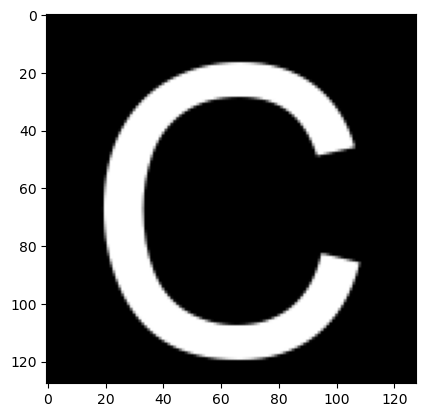

In [39]:
plt.imshow(C,cmap = 'gray')

In [126]:
H = 128
W = 128
pad_factor = 1
A_input = build_input(H = H, W = W,width = 32) 
A_target = build_pbb_target(pad_factor=pad_factor, n=6, H=H, W=W, width=12.8*4)
# A_target = torch.tensor(C) + 1e-8
m = SLMphaseRetrievalCG(A_in = A_input,A_t = A_target,pad_factor=pad_factor,H = H,W = W)

/Users/apple/Desktop/holography/src/gradient.py:128: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.A_in = self.pad(torch.tensor(A_in / FeedbackHologram._norm(A_in), dtype=torch.float32))
/Users/apple/Desktop/holography/src/gradient.py:134: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.A_t = torch.tensor(A_t / FeedbackHologram._norm(A_t), dtype=torch.float32)


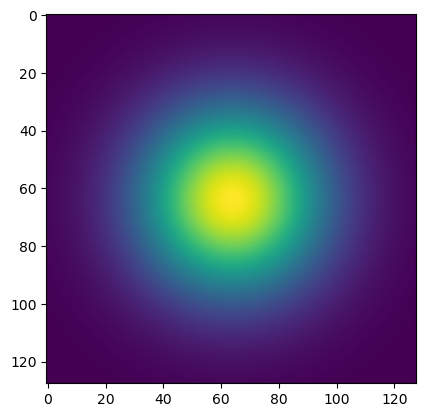

In [127]:
plt.imshow(m.A_in)

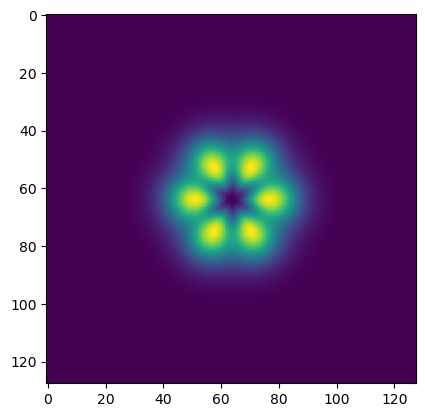

In [128]:
plt.imshow((m.A_t).cpu().detach().numpy())

In [131]:
ot_phase,ot_out = ot_phase_retrieval(((m.A_in)**2),(m.A_t**2),reg_param=8e-4,n_iters=100)

torch.Size([16384, 16384])


In [132]:
ot_out.errors

Array([ 4.6714264e-01,  3.3606911e-01,  2.5954157e-01,  2.0349389e-01,
        1.6021696e-01,  1.2605628e-01,  9.9014789e-02,  7.7526972e-02,
        6.0578659e-02,  4.7252394e-02,  3.6813758e-02,  2.8651915e-02,
        2.2279097e-02,  1.7310735e-02,  1.3442722e-02,  1.0434514e-02,
        8.0970880e-03,  6.2817102e-03,  4.8723803e-03,  3.7786704e-03,
        2.9301206e-03,  2.2719610e-03,  1.7614467e-03,  1.3656028e-03,
        1.0586536e-03,  8.2066632e-04, -1.0000000e+00, -1.0000000e+00,
       -1.0000000e+00, -1.0000000e+00, -1.0000000e+00, -1.0000000e+00,
       -1.0000000e+00, -1.0000000e+00, -1.0000000e+00, -1.0000000e+00,
       -1.0000000e+00, -1.0000000e+00, -1.0000000e+00, -1.0000000e+00,
       -1.0000000e+00, -1.0000000e+00, -1.0000000e+00, -1.0000000e+00,
       -1.0000000e+00, -1.0000000e+00, -1.0000000e+00, -1.0000000e+00,
       -1.0000000e+00, -1.0000000e+00, -1.0000000e+00, -1.0000000e+00,
       -1.0000000e+00, -1.0000000e+00, -1.0000000e+00, -1.0000000e+00,
      

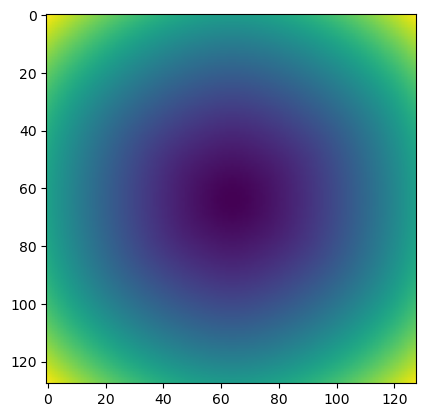

In [133]:
plt.imshow((ot_phase*(torch.pi*2)).cpu().detach().numpy())

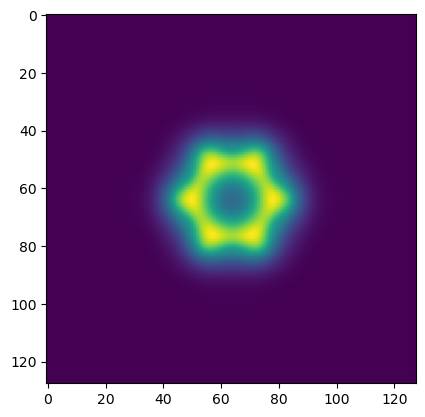

In [134]:
out = m.forward_propagate(m.A_in*torch.exp(ot_phase*1j*torch.pi*2),z = 0)
plt.imshow((out.abs()).numpy())

In [135]:
temp,cgot = m.solve(x0 = ot_phase.numpy(), max_iter=1000)

         Current function value: 3420468.750000
         Iterations: 1000
         Function evaluations: 1453


In [139]:
temp,cg = m.solve( max_iter=1000)

         Current function value: 3979475.750000
         Iterations: 1000
         Function evaluations: 1494


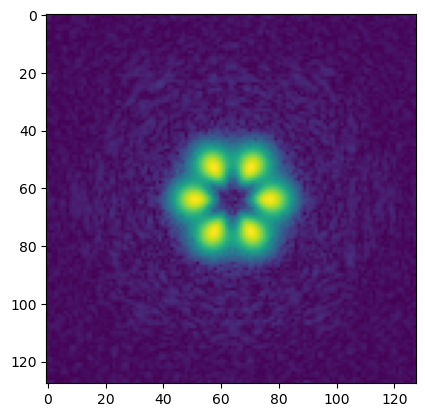

In [140]:
plt.imshow(cgot)

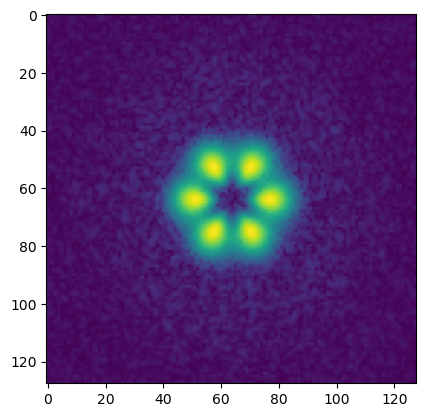

In [141]:
plt.imshow(cg)